# JANUS: QLoRA Fine-Tuning vs Prompt Engineering

**Banking77 intent classification with Qwen2.5-1.5B-Instruct, MLflow tracking and a CI/CD quality gate**

Repository: https://github.com/IamKD64/janus-llm

---

## Overview

This notebook runs the complete JANUS experiment end to end on a Kaggle GPU. It answers one practical question:

> For a narrow, high-volume task, is it worth fine-tuning a small open LLM with QLoRA, or can careful prompt engineering get you there?

The task is **Banking77**: classify a customer-support message into one of **77 banking intents** (for example `card_arrival` or `lost_or_stolen_card`). It is a good stress test because a prompt has to describe 77 labels, while a fine-tuned model can learn them.

## Experiment at a glance

| Item | Setting |
|---|---|
| Dataset | `PolyAI/banking77` (77 intents) |
| Base model | `Qwen/Qwen2.5-1.5B-Instruct`, loaded in 4-bit (NF4, double quantization) |
| Fine-tuning | QLoRA: LoRA rank 16, alpha 32, dropout 0.05, all linear layers |
| Prompt baselines | zero-shot, few-shot (5 examples), one-example-per-label |
| Fine-tuning data | 3,000 training examples, 200 validation examples (carved from train) |
| Evaluation | 1,000 held-out test examples, identical for every run |
| Metrics | accuracy (bootstrap 95% CI), macro-F1, invalid-output rate, prompt tokens, latency |
| Tracking / registry | MLflow (SQLite backend), Model Registry alias `champion` |
| Release gate | fine-tune must beat the best prompt baseline by at least 0.05 macro-F1, with accuracy of at least 0.80 and an invalid rate of at most 2% |
| Hardware | Kaggle, 2x Tesla T4 (15 GB each) |
| Seed / decoding | seed 42, greedy decoding |

## Results at a glance

| Run | Accuracy (95% CI) | Macro-F1 | Invalid % | Prompt tokens | ms / sample |
|---|---|---|---|---|---|
| Zero-shot prompt | 0.407 (0.375-0.439) | 0.382 | 2.9 | 514 | 732 |
| Few-shot prompt | 0.424 (0.391-0.454) | 0.404 | 3.5 | 637 | 905 |
| One-per-label prompt (best baseline) | 0.451 (0.420-0.478) | 0.427 | 3.4 | 1,959 | 2,594 |
| **QLoRA fine-tune** | **0.870 (0.850-0.890)** | **0.870** | **0.0** | 515 | 813 |

The quality gate passed with a macro-F1 gain of **+0.443** over the best prompt baseline, and the adapter was registered in MLflow as `banking77-qlora-adapter` v1 (alias `champion`).

## Notebook map

1. Setup: verify the code version, check the GPU, install the project
2. Smoke test: a fast end-to-end pipeline check on a tiny configuration
3. Full experiment: prompt baselines, troubleshooting, QLoRA training, fine-tuned evaluation
4. Report, quality gate and model registry
5. Results display and artifact export
6. Conclusions and limitations

## Reproducibility notes

- Code version: commit `d7460d7` of the repository above (confirmed in section 1.1).
- Internet access must be **On** in the Kaggle notebook settings (model and dataset downloads).
- Run the cells in order. Sections 3.1 and 3.4 are long-running; see the notes on each.
- The noisy line "Could not find cuda drivers on your machine, GPU will not be used" in several outputs comes from a TensorFlow package installed on Kaggle. It does not affect PyTorch, which does use the GPU (verified in section 3.2).

---
# 1. Setup

Confirm exactly which version of the code is being run, check the hardware, and install the project.

### 1.1 Verify the remote code version

Asks GitHub for the latest commit on the default branch without downloading anything. The commit hash is recorded here so the run can be reproduced exactly.

- **Expected output:** a single commit hash (here `d7460d7...`).

In [11]:
!git ls-remote https://github.com/IamKD64/janus-llm.git HEAD

d7460d7af5b11388b5bc687e2290a7b1660aae1f	HEAD


### 1.2 Check GPU, clone the repository and install

Runs four steps in one cell:

1. `nvidia-smi` prints the GPU model and driver version.
2. `git clone` downloads the project into `/kaggle/working`.
3. `%cd` moves into the project folder.
4. `pip install -e ".[train,dev]"` installs the `p3ft` package in editable mode, together with the training stack (PyTorch, Transformers, PEFT, bitsandbytes, Accelerate, Datasets) and the dev tools.

- **Expected output:** the date/driver header, git clone progress, then pip build messages ending in `done`.

In [12]:
!nvidia-smi | head -5
!git clone https://github.com/IamKD64/janus-llm.git
%cd /kaggle/working/janus-llm
!pip install -q -e ".[train,dev]"

Sat Nov 28 05:14:39 2026
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
Cloning into 'janus-llm'...
remote: Enumerating objects: 86, done.
remote: Counting objects: 100% (86/86), done.
remote: Compressing objects: 100% (64/64), done.
remote: Total 86 (delta 20), reused 81 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (86/86), 244.69 KiB | 1.51 MiB/s, done.
Resolving deltas: 100% (20/20), done.
/kaggle/working/janus-llm
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for p3ft (pypro

### 1.3 List the available GPUs

Lists every GPU visible to the notebook.

- **Observed:** two Tesla T4 GPUs (GPU 0 and GPU 1). This matters later: with two GPUs visible, Hugging Face may place model layers on both unless `CUDA_VISIBLE_DEVICES` restricts it.

In [14]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-c80e91d8-3b7d-4a09-3865-a6352a8f9fcb)
GPU 1: Tesla T4 (UUID: GPU-d31a140e-995f-1067-9a31-71d7133377b2)


---
# 2. Smoke Test

### 2.1 Run the whole pipeline on a tiny configuration

`make smoke` runs the **entire** pipeline using `configs/smoke.yaml`: baselines, QLoRA training, fine-tuned evaluation, report and quality gate. It uses a smaller model (Qwen2.5-0.5B-Instruct), only 300 training examples and 100 evaluation examples, so it finishes in minutes.

`CUDA_VISIBLE_DEVICES=0` restricts the run to a single GPU.

- **Purpose:** prove that every stage works before spending hours on the real run. The numbers are **not** meaningful results.
- **Observed:** zero-shot 17% and few-shot 36% accuracy; the fine-tuned adapter reached 41% with 0% invalid outputs after one short epoch (38 steps, about 5 minutes). The smoke-test gate thresholds are set to zero, so it passes by design.

In [20]:
!CUDA_VISIBLE_DEVICES=0 make smoke

make all CFG=configs/smoke.yaml
make[1]: Entering directory '/kaggle/working/janus-llm'
python -m p3ft.evaluate --config configs/smoke.yaml --mode baseline
I0000 00:00:1795843279.732159     658 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

=== baseline: zero_shot ===
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
{
  "accuracy": 0.17,
  "accuracy_ci_low": 0.1,
  "accuracy_ci_high": 0.25,
  "macro_f1": 0.14206349206349206,
  "invalid_rate": 0.17,
  "avg_latency_ms": 210.44959299999846,
  "avg_prompt_tokens": 513.82
}

=== baseline: few_shot ===
{
  "accuracy": 0.36,
  "accuracy_ci_low": 0.26975000000000005,
  "accuracy_ci_high": 0.45024999999999976,
  "macro_f1": 0.3141156462585034,
  "invalid_rate": 0.24,
  "avg_latency_ms": 268.3320465500037,
  "avg_prompt_tokens": 651.82
}
python -m p3ft.train --config configs/smoke.yaml
I0000 00:00:1795843

---
# 3. Full Experiment

### 3.1 Prompt baselines (and a first training attempt)

`make all` runs baselines, training, fine-tuned evaluation, report and gate in sequence, using `configs/default.yaml`.

- **Baselines completed.** The three prompt strategies were evaluated on the same 1,000 held-out examples (about 70 minutes of generation in total). These are the baseline numbers used in the final report:

| Baseline | Accuracy | Macro-F1 | Prompt tokens |
|---|---|---|---|
| zero_shot | 0.407 | 0.382 | 514 |
| few_shot | 0.424 | 0.404 | 637 |
| one_per_label | 0.451 | 0.427 | 1,959 |

- **Training then failed** at step 0 of 376 with `CUDA error: unspecified launch failure`, so `make all` stopped (`Error 1`). The following cells check the GPUs and retry training with a smaller micro-batch. The exact root cause was not confirmed.
- **Note:** do not re-run this cell to resume. It would repeat the ~70-minute baseline evaluation. Run the individual stages instead (sections 3.4 onward).

In [21]:
!make all

python -m p3ft.evaluate --config configs/default.yaml --mode baseline
2026/11/28 05:30:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/28 05:30:51 INFO mlflow.store.db.utils: Updating database tables
2026/11/28 05:30:53 INFO mlflow.tracking.fluent: Experiment with name 'p3-qlora-vs-prompting' does not exist. Creating a new experiment.
tokenizer_config.json: 7.30kB [00:00, 26.0MB/s]
vocab.json: 2.78MB [00:00, 38.8MB/s]
merges.txt: 1.67MB [00:00, 134MB/s]
tokenizer.json: 7.03MB [00:00, 193MB/s]
config.json: 100%|█████████████████████████████| 660/660 [00:00<00:00, 5.41MB/s]
I0000 00:00:1795843864.595318     778 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
model.safetensors: 100%|████████████████████| 3.09G/3.09G [00:07<00:00, 416MB/s]
generation_config.json: 100%|██████████████████| 242/242 [00:00<00:00, 1.62MB/s]

=== baseline: zero_shot ===
The following generation flags are not valid and may be ignored: ['tempe

### 3.2 Troubleshooting: GPU health checks

The next three cells check whether the failure came from the hardware or the environment.

#### 3.2.1 GPU status

Shows memory use and running processes for both GPUs.

- **Observed:** both T4s idle with 0 MiB of 15,360 MiB used and no leftover processes, so no other job was holding GPU memory.

In [22]:
!nvidia-smi

Sat Nov 28 06:44:00 2026
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+------------

#### 3.2.2 PyTorch and CUDA visibility

Confirms that PyTorch can see the GPUs.

- **Observed:** PyTorch 2.11.0 (CUDA 13.0 build), CUDA available, 2 devices (Tesla T4 each).

In [23]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA devices:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

PyTorch: 2.11.0+cu130
CUDA available: True
CUDA devices: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


#### 3.2.3 CUDA compute test

Multiplies a 2048x2048 matrix on each GPU and synchronizes, to prove that the GPUs can execute kernels.

- **Observed:** both GPUs completed the computation successfully, so the hardware is healthy and the earlier error was not a general GPU fault. Training is retried below with a much smaller micro-batch.

In [24]:
import torch

for i in range(torch.cuda.device_count()):
    x = torch.randn(2048, 2048, device=f"cuda:{i}")
    y = x @ x
    torch.cuda.synchronize(i)
    print(f"GPU {i}: CUDA computation successful")

GPU 0: CUDA computation successful
GPU 1: CUDA computation successful


### 3.3 Review the experiment configuration

Prints `configs/default.yaml`, the single source of truth for the run: dataset sizes, model, QLoRA settings, training hyperparameters, evaluation settings, MLflow location and the quality-gate thresholds.

- **Key values:** 3,000 training / 200 validation / 1,000 evaluation examples; LoRA rank 16; 2 epochs; learning rate 2e-4; gate requires +0.05 macro-F1, 0.80 accuracy and at most 2% invalid outputs.
- The training cell below overrides `batch_size` and `grad_accum` on the command line rather than editing this file.

In [25]:
!cat configs/default.yaml

# Main experiment: Banking77 intent classification (77 classes).
seed: 42

data:
  dataset: PolyAI/banking77
  train_size: 3000      # fine-tuning examples (null = all ~9.8k)
  val_size: 200         # carved out of train, used for eval_loss only
  eval_size: 1000       # held-out test examples (null = all 3080)

model:
  name: Qwen/Qwen2.5-1.5B-Instruct
  max_seq_len: 1024

qlora:
  quantize: true        # 4-bit NF4 + double quant
  r: 16
  alpha: 32
  dropout: 0.05
  target_modules: all-linear

train:
  output_dir: outputs/qlora-banking77
  epochs: 2
  batch_size: 8
  grad_accum: 2
  lr: 0.0002
  warmup_ratio: 0.03
  lr_scheduler: cosine
  logging_steps: 10

eval:
  batch_size: 8
  max_new_tokens: 16
  quantize_baseline: true   # same 4-bit base for baselines => apples-to-apples
  strategies: [zero_shot, few_shot, one_per_label]
  few_shot_k: 5

mlflow:
  tracking_uri: sqlite:///mlflow.db
  experiment: p3-qlora-vs-prompting
  registered_model: banking77-qlora-adapter

results_dir: res

### 3.4 QLoRA fine-tuning

Trains the LoRA adapter on the 4-bit quantized base model. The overrides `train.batch_size=1 train.grad_accum=16` use a micro-batch of 1 and accumulate gradients over 16 steps, for an **effective batch size of 16** while keeping GPU memory low.

How the training works:

- The model sees a chat-formatted prompt followed by the intent label, and the loss is computed **only on the label tokens**.
- Only the LoRA adapter weights are trained: **18,464,768 trainable parameters (2.04%)** as reported by PEFT.
- Metrics and parameters are logged to MLflow, and the adapter is saved to `outputs/qlora-banking77`.

**Observed:**

| Item | Value |
|---|---|
| Optimizer steps | 376 (2 epochs) |
| Training time | about 4 h 45 min (17,129 s) |
| Average training loss | 0.152 |
| Final validation loss | 0.104 |
| MLflow run id | `a44b18f11f1f428585725d1919f54688` |

**Note on speed:** training is slow (about 38 s per step) because each example is roughly 515 tokens long, the same length as the zero-shot prompt. That suggests the fine-tuning prompt includes the full 77-label list. A shorter fine-tuning prompt would train much faster.

The progress bars below have been collapsed to their final state to keep the notebook readable.

In [26]:
!python -m p3ft.train --config configs/default.yaml --set train.batch_size=1 train.grad_accum=16

I0000 00:00:1795848489.997390     921 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train=3000 (dropped 0)  val=200 (dropped 0)
trainable params: 18,464,768 / 907,081,216 (2.04%)
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.
  0%|                                                   | 0/376 [00:00<?, ?it/s]`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
{'loss': 0.6999, 'grad_norm': 4.669649600982666, 'learning_rate': 0.00015000000000000001, 'epoch': 0.05}
{'loss': 0.4022, 'grad_norm': 2.698016881942749, 'learning_rate': 0.00019981755542233177, 'epoch': 0.11}
{'loss': 0.3532, 'grad_norm': 1.4956926107406616, 'learning_rate': 0.00019892555156666089, 'epoch': 0.16}
{'loss': 0.3098, 'grad_nor

### 3.5 Evaluate the fine-tuned model

Loads the base model, attaches the saved adapter, and evaluates on the **same 1,000 held-out examples** used for the baselines, with greedy decoding.

- **Observed:**

| Metric | Value |
|---|---|
| Accuracy | 0.870 (95% CI 0.850-0.890) |
| Macro-F1 | 0.870 |
| Invalid-output rate | 0.0% |
| Average prompt tokens | 515 |
| Latency | about 813 ms per sample |

Compared with the strongest prompt baseline (accuracy 0.451), the fine-tuned model roughly doubles accuracy and removes invalid outputs entirely. Results are written to `results/finetuned-qlora.json` and logged to MLflow.

In [27]:
!python -m p3ft.evaluate --config configs/default.yaml --mode finetuned

I0000 00:00:1795866063.332692     976 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

=== fine-tuned QLoRA adapter ===
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
{
  "accuracy": 0.87,
  "accuracy_ci_low": 0.85,
  "accuracy_ci_high": 0.89,
  "macro_f1": 0.8702017096817564,
  "invalid_rate": 0.0,
  "avg_latency_ms": 812.7560227040121,
  "avg_prompt_tokens": 514.72
}


---
# 4. Report, Quality Gate and Model Registry

### 4.1 Generate the comparison report

Reads every result file in `results/` and writes two artifacts:

- `results/REPORT.md`: comparison table, takeaways and the most common fine-tuned errors.
- `results/comparison.png`: bar chart of accuracy and macro-F1 for every run.

In [28]:
!python -m p3ft.report --config configs/default.yaml

Wrote results/REPORT.md and results/comparison.png


### 4.2 Run the quality gate

Applies the release rule from the configuration. The fine-tuned model must beat the **best** prompt baseline, not just the weakest one. The command exits with an error if any check fails, which is how CI/CD blocks a bad release.

| Check | Requirement | Observed | Result |
|---|---|---|---|
| Macro-F1 gain vs best baseline | at least +0.05 | +0.443 | PASS |
| Accuracy | at least 0.80 | 0.870 | PASS |
| Invalid-output rate | at most 2% | 0.0% | PASS |

In [29]:
!python -m p3ft.quality_gate --config configs/default.yaml

[PASS] macro-F1 gain +0.443 vs baseline-one_per_label (need >= 0.05)
[PASS] accuracy 0.870 (need >= 0.8)
[PASS] invalid rate 0.000 (need <= 0.02)
QUALITY GATE: PASSED


### 4.3 Promote the adapter in the MLflow Model Registry

Runs the same gate again with `--promote`. Because it passes, the training run's adapter is registered as **`banking77-qlora-adapter` version 1** and given the alias **`champion`**, together with its metrics as version tags.

- **Why this is a separate step:** promotion only happens after the gate passes, so a regression can never become the champion model.

In [30]:
!make promote

python -m p3ft.quality_gate --config configs/default.yaml --promote
[PASS] macro-F1 gain +0.443 vs baseline-one_per_label (need >= 0.05)
[PASS] accuracy 0.870 (need >= 0.8)
[PASS] invalid rate 0.000 (need <= 0.02)
QUALITY GATE: PASSED
Registered: banking77-qlora-adapter v1 -> alias 'champion'


---
# 5. Results Display and Artifact Export

### 5.1 Package the results and the adapter

Creates two archives for download:

- `results.zip`: result JSON files, `REPORT.md` and the chart (per-example predictions excluded).
- `adapter.zip`: the saved LoRA adapter, tokenizer files and label list.

Commit the small result files to the repository so CI can re-run the quality gate on them. The adapter is large, so host it elsewhere (for example the Hugging Face Hub) rather than in Git.

In [31]:
!zip -r results.zip results/ -x 'results/predictions/*'
!zip -r adapter.zip outputs/qlora-banking77/

  adding: results/ (stored 0%)
  adding: results/finetuned-qlora.json (deflated 62%)
  adding: results/REPORT.md (deflated 44%)
  adding: results/comparison.png (deflated 17%)
  adding: results/baseline-one_per_label.json (deflated 65%)
  adding: results/.gitkeep (stored 0%)
  adding: results/baseline-few_shot.json (deflated 64%)
  adding: results/baseline-zero_shot.json (deflated 65%)
  adding: outputs/qlora-banking77/ (stored 0%)
  adding: outputs/qlora-banking77/adapter_config.json (deflated 61%)
  adding: outputs/qlora-banking77/README.md (deflated 65%)
  adding: outputs/qlora-banking77/tokenizer_config.json (deflated 89%)
  adding: outputs/qlora-banking77/tokenizer.json (deflated 81%)
  adding: outputs/qlora-banking77/labels.json (deflated 64%)
  adding: outputs/qlora-banking77/chat_template.jinja (deflated 71%)
  adding: outputs/qlora-banking77/added_tokens.json (deflated 67%)
  adding: outputs/qlora-banking77/special_tokens_map.json (deflated 69%)
  adding: outputs/qlora-banking

### 5.2 Display the report and chart

Renders `REPORT.md` and `comparison.png` inline so the final comparison can be read without leaving the notebook.

# Results: QLoRA fine-tune vs prompt engineering

Model: `Qwen/Qwen2.5-1.5B-Instruct` | eval set: 1000 held-out Banking77 test examples | seed 42

| Run | Accuracy (95% CI) | Macro-F1 | Invalid % | Prompt tokens | ms/sample |
|---|---|---|---|---|---|
| finetuned-qlora | 0.870 (0.850-0.890) | 0.870 | 0.0 | 515 | 813 |
| baseline-one_per_label | 0.451 (0.420-0.478) | 0.427 | 3.4 | 1959 | 2594 |
| baseline-few_shot | 0.424 (0.391-0.454) | 0.404 | 3.5 | 637 | 905 |
| baseline-zero_shot | 0.407 (0.375-0.439) | 0.382 | 2.9 | 514 | 732 |

## Takeaways
- Fine-tuned macro-F1 is **+0.443** vs the best prompt baseline (`baseline-one_per_label`).
- The fine-tuned prompt is 3.8x shorter (515 vs 1959 tokens), which is where the inference-cost savings come from.

## Most common fine-tuned errors

| True | Predicted | Count |
|---|---|---|
| card_acceptance | supported_cards_and_currencies | 7 |
| card_delivery_estimate | card_arrival | 6 |
| transfer_not_received_by_recipient | pending_transfer | 4 |
| topping_up_by_card | top_up_reverted | 4 |
| beneficiary_not_allowed | failed_transfer | 3 |


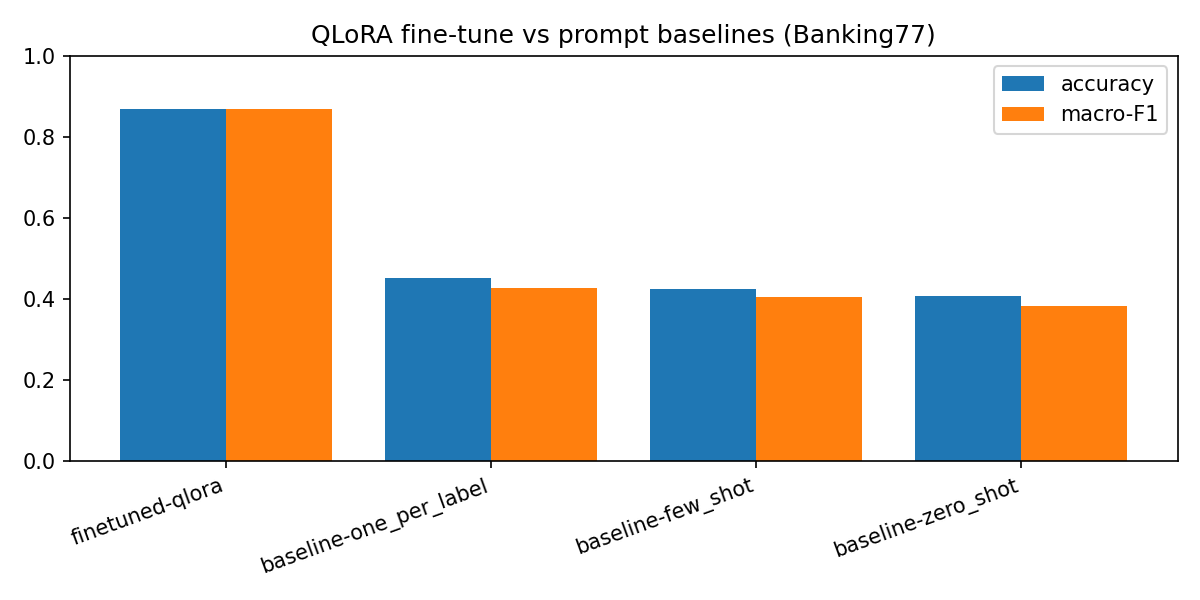

In [32]:
from IPython.display import Image, Markdown, display

display(Markdown(open("results/REPORT.md").read()))
display(Image("results/comparison.png"))

### 5.3 Download link for the full archive

Creates a clickable download link for `janus-llm-results.zip`. The archive itself is created by the next cell, so the link only works after that cell has run.

In [33]:
from IPython.display import FileLink

FileLink("/kaggle/working/janus-llm-results.zip")

/kaggle/working/janus-llm-results.zip

### 5.4 Create a full archive of the working directory

Zips everything in `/kaggle/working` (the repository, results, adapter and MLflow database), skipping notebook checkpoints and the archive itself. This is a convenient backup because Kaggle session files are deleted when the session ends.

- **Observed:** the archive is about 375 MB.

In [34]:
import os
import zipfile

source_dir = "/kaggle/working"
zip_path = "/kaggle/working/janus-llm-results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(source_dir):
        # Avoid including the ZIP inside itself
        dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

        for file in files:
            full_path = os.path.join(root, file)

            if full_path == zip_path:
                continue

            arcname = os.path.relpath(full_path, source_dir)
            z.write(full_path, arcname)

print("ZIP created:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

ZIP created: /kaggle/working/janus-llm-results.zip
Size: 375.49 MB


---
# 6. Conclusions and Limitations

## Findings

- **Fine-tuning clearly beat prompting on this task.** Accuracy rose from 40.7% (zero-shot) and 45.1% (best prompt) to **87.0%**, and invalid outputs dropped from about 3% to 0%.
- **The gain holds at equal prompt length.** The fine-tuned run used a prompt of about the same length as zero-shot (515 vs 514 tokens), so the improvement comes from the learned weights, not from a longer prompt.
- **It is cheaper than the strongest prompt.** Compared with the one-per-label prompt, it needs 3.8x fewer prompt tokens and about 3x less time per sample (813 ms vs 2,594 ms).
- **Remaining errors are between near-duplicate intents:** `card_acceptance` vs `supported_cards_and_currencies`, `card_delivery_estimate` vs `card_arrival`, `transfer_not_received_by_recipient` vs `pending_transfer`.

## Limitations

- Single training run and a single seed; the 1,000-example evaluation gives a confidence interval of roughly plus or minus 2 points.
- The model was trained on 3,000 of the roughly 9,800 available training examples. More data or more epochs would likely improve accuracy.
- Training took about 4 h 45 min because the fine-tuning prompt is long. There is no per-token cost saving against the zero-shot prompt, only against the longer few-shot and one-per-label prompts.
- Latency is measured per sample at batch size 8 on one shared GPU setup, so treat it as a relative comparison.

## Next steps

1. Retrain with a short fine-tuning prompt to measure the training-time and inference-cost savings directly.
2. Repeat with several seeds and report mean and standard deviation.
3. Sweep the LoRA rank and learning rate, using MLflow to compare runs.
4. Publish the adapter to the Hugging Face Hub and deploy the FastAPI service from the Docker image built by the CD workflow.